# Where does CQL lose revenue?

I use the saved baseline policies to find where CQL differs from the optimum, how much revenue those decisions lose, and how many training examples support them.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data/source.json").exists())
sys.path.insert(0, str(ROOT))
from hotel_pricing.environment import load_config
from hotel_pricing.offline_data import load_dataset
from hotel_pricing.policy_gap import explain_gap

config = load_config(ROOT / "configs/environment.json")
DATA = ROOT / "data/simulated/baseline"
RUN = ROOT / "outputs/baseline/cql"
OUT = ROOT / "outputs/baseline/gap_diagnosis"
OUT.mkdir(parents=True, exist_ok=True)
original = json.loads((RUN / "results.json").read_text())
assert hashlib.sha256((DATA / "manifest.json").read_bytes()).hexdigest() == original["dataset_manifest_sha256"]
training = load_dataset(DATA, "train")
with np.load(RUN / "policies.npz") as saved:
    policies = {f"CQL seed {seed}": saved[f"CQL seed {seed}"] for seed in [0,1,2]}
prices = np.array(config.prices)
diagnoses = {name: explain_gap(config, policy, training) for name, policy in policies.items()}


## 1. Compare the prices

I plot each policy's price at every state. Time runs from 330 days left to 1; lower rows have fewer rooms. Gray cells are unreachable.

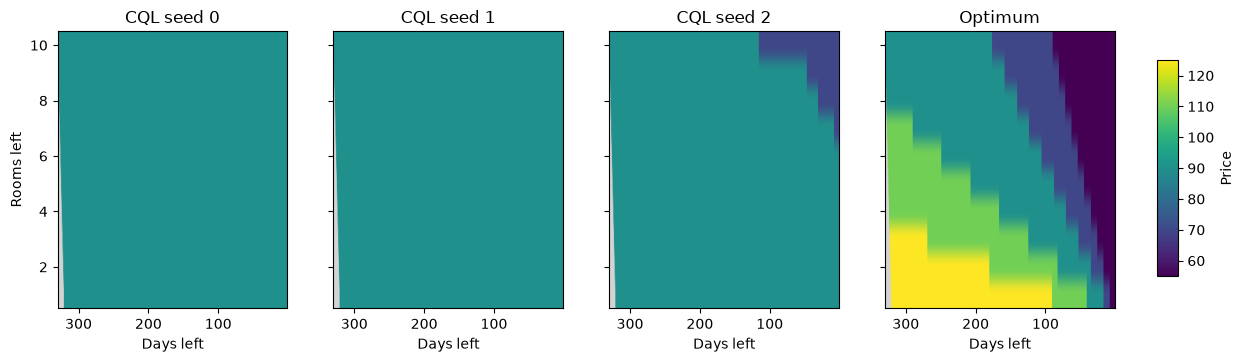

In [2]:
time, rooms = np.indices((config.horizon+1, config.capacity+1))
reachable = (time>0) & (rooms>0) & (config.capacity-rooms <= config.horizon-time)
fig, axes = plt.subplots(1,4,figsize=(14,3.6),sharey=True)
for ax, (name, actions) in zip(axes, [*policies.items(), ("Optimum", diagnoses["CQL seed 0"]["optimal_actions"])]):
    values = prices[actions].astype(float)
    values[~reachable] = np.nan
    ax.set_facecolor("lightgray")
    image = ax.imshow(values[1:,1:].T, origin="lower", aspect="auto", extent=[1,330,.5,10.5], vmin=55,vmax=125,cmap="viridis")
    ax.invert_xaxis()
    ax.set(title=name,xlabel="Days left")
axes[0].set_ylabel("Rooms left")
fig.subplots_adjust(right=.88)
fig.colorbar(image,cax=fig.add_axes([.91,.2,.015,.6]),label="Price")
plt.show()

Seeds 0 and 1 always choose 90. Seed 2 sometimes lowers the price when many rooms remain. The optimum responds more to time and inventory.

Different prices may have similar values, so disagreement alone does not tell us how much revenue is lost.

## 2. Measure the loss

At each state, I compare choosing the optimal price with choosing CQL's price, assuming optimal decisions afterward. The difference is the **local decision loss**, including the value of rooms kept for later.

I then weight it by the probability that CQL reaches that state:

`gap contribution = CQL reach probability × local decision loss`

Summing these contributions gives the full revenue gap without counting future losses twice. The calculation uses known simulator probabilities, not the network's predicted values.

In [3]:
tables = {}
summary = []
for name, diagnostic in diagnoses.items():
    chosen = policies[name]
    optimal = diagnostic["optimal_actions"]
    counts = diagnostic["counts"]
    table = pd.DataFrame({
        "days_left": time[reachable], "rooms_left": rooms[reachable],
        "cql_price": prices[chosen[reachable]], "optimal_price": prices[optimal[reachable]],
        "local_loss": diagnostic["local_loss"][reachable],
        "reach_probability": diagnostic["visits"][reachable],
        "gap_contribution": diagnostic["contribution"][reachable],
        "cql_action_count": np.take_along_axis(counts, chosen[...,None], axis=2)[...,0][reachable],
        "optimal_action_count": np.take_along_axis(counts, optimal[...,None], axis=2)[...,0][reachable],
    })
    tables[name] = table
    table.to_csv(OUT / (name.replace(" ","_")+"_states.csv"),index=False)
    weighted_mismatch = np.sum(table.reach_probability*(table.cql_price!=table.optimal_price))/table.reach_probability.sum()
    summary.append({"Policy":name, "Revenue gap":diagnostic["gap"],
                    "Sum of state contributions":table.gap_contribution.sum(),
                    "Disagreement across expected CQL visits (%)":100*weighted_mismatch})
display(pd.DataFrame(summary).round(4))


,Policy,Revenue gap,Sum of state contributions,Disagreement across expected CQL visits (%)
0,CQL seed 0,37.4073,37.4073,34.0250
1,CQL seed 1,37.4073,37.4073,34.0250
2,CQL seed 2,37.3280,37.3280,34.0236


The contributions add up to about **37.4 revenue units**, matching the total gap. These values depend on our assumed demand model.

## 3. Locate the largest contributions

I use seed 0 for the detailed plots because seeds 0 and 1 are identical. Tables are saved for all three seeds.

The maps show local loss, CQL's reach probability, and their product. Each has its own color scale.

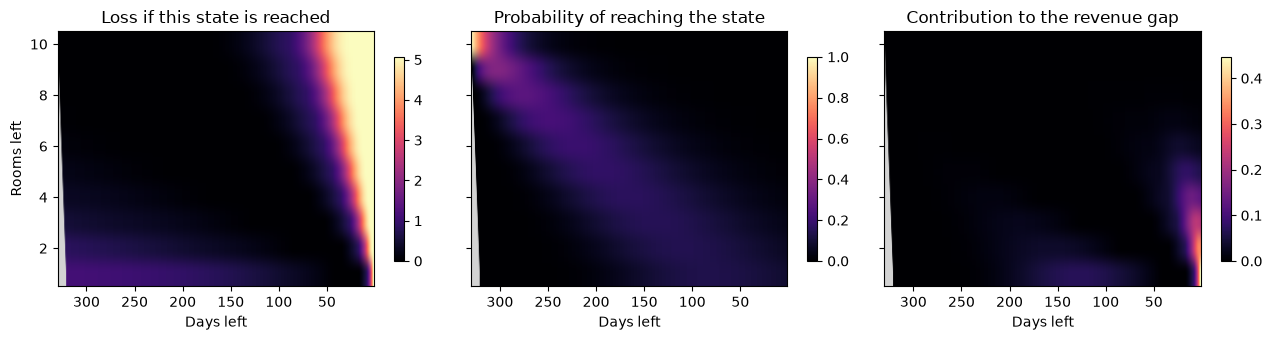

,days_left,rooms_left,cql_price,optimal_price,local_loss,reach_probability,gap_contribution,cql_action_count,optimal_action_count
0,1,1,90,55,5.06893,0.08816,0.44689,21,3
10,2,1,90,55,4.10712,0.08899,0.36548,15,4
11,2,2,90,55,5.06893,0.06632,0.33619,4,4
1,1,2,90,55,5.06893,0.06550,0.33204,7,2
21,3,2,90,55,4.92306,0.06715,0.33057,6,3
31,4,2,90,55,4.67556,0.06798,0.31783,6,3
41,5,2,90,55,4.36061,0.06881,0.30006,8,1
20,3,1,90,55,3.29117,0.08981,0.29559,18,3
51,6,2,90,55,4.00437,0.06965,0.27890,9,0
61,7,2,90,55,3.62661,0.07049,0.25565,8,0


In [4]:
name = "CQL seed 0"
diagnostic = diagnoses[name]
table = tables[name]
fig, axes = plt.subplots(1,3,figsize=(13,3.5),sharey=True)
for ax, key, title in zip(axes,["local_loss","visits","contribution"],
                          ["Loss if this state is reached", "Probability of reaching the state", "Contribution to the revenue gap"]):
    values = diagnostic[key].copy()
    values[~reachable] = np.nan
    ax.set_facecolor("lightgray")
    image = ax.imshow(values[1:,1:].T,origin="lower",aspect="auto",extent=[1,330,.5,10.5],cmap="magma",vmin=0)
    ax.invert_xaxis()
    ax.set(title=title,xlabel="Days left")
    fig.colorbar(image,ax=ax,shrink=.8)
axes[0].set_ylabel("Rooms left")
plt.tight_layout()
plt.show()
display(table.nlargest(10,"gap_contribution").round(5))

A large local loss matters little if CQL rarely reaches that state. Small losses across frequently visited states can matter more.

I group contributions by time and inventory to see the broader pattern.

rooms_group,1–2,3–5,6–10
time_group,,,
1–30,6.133,9.831,1.470
31–90,1.495,2.424,1.795
91–180,8.022,0.746,0.278
181–330,2.470,2.614,0.127


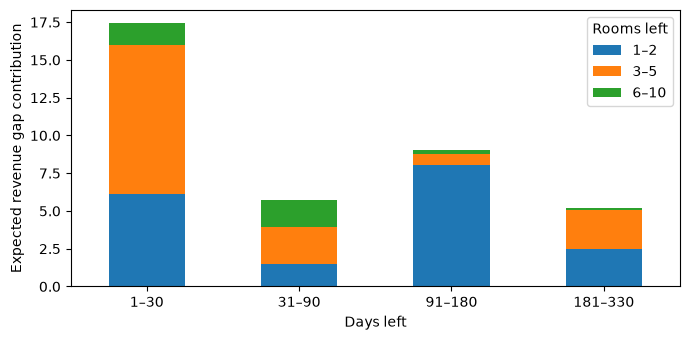

In [5]:
table = table.copy()
table["time_group"] = pd.cut(table.days_left,[0,30,90,180,330],labels=["1–30","31–90","91–180","181–330"])
table["rooms_group"] = pd.cut(table.rooms_left,[0,2,5,10],labels=["1–2","3–5","6–10"])
regions = table.groupby(["time_group","rooms_group"],observed=True).gap_contribution.sum().unstack(fill_value=0)
display(regions.round(3))
regions.plot.bar(stacked=True,figsize=(7,3.5),rot=0)
plt.xlabel("Days left")
plt.ylabel("Expected revenue gap contribution")
plt.legend(title="Rooms left")
plt.tight_layout()
plt.show()


## 4. Check training support

I count training examples for CQL's action and the optimal action at each state. I then group the loss by optimal-action counts: 0, 1–4, 5–19, and 20+. These are descriptive thresholds, not guarantees of reliable learning.

,Policy,Optimal-action examples,Gap contribution,Share of gap (%)
0,CQL seed 0,0,9.188,24.563
1,CQL seed 0,1–4,11.890,31.786
2,CQL seed 0,5–19,7.640,20.425
3,CQL seed 0,20+,8.688,23.226
4,CQL seed 1,0,9.188,24.563
5,CQL seed 1,1–4,11.890,31.786
6,CQL seed 1,5–19,7.640,20.425
7,CQL seed 1,20+,8.688,23.226
8,CQL seed 2,0,9.105,24.392
9,CQL seed 2,1–4,11.894,31.864


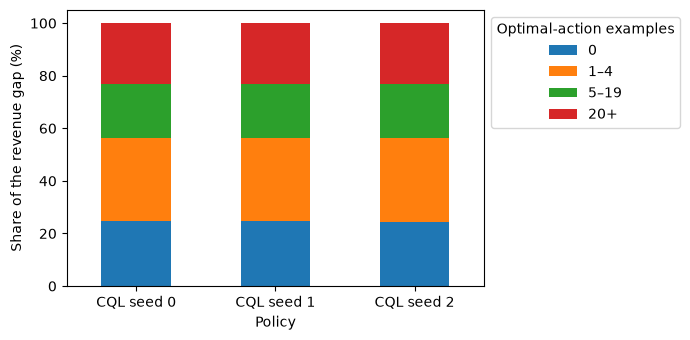

In [6]:
support_rows = []
for name, state_table in tables.items():
    state_table = state_table.copy()
    state_table["support"] = pd.cut(state_table.optimal_action_count,[-1,0,4,19,np.inf],labels=["0","1–4","5–19","20+"])
    grouped = state_table.groupby("support",observed=False).gap_contribution.sum()
    for group, value in grouped.items():
        support_rows.append({"Policy":name,"Optimal-action examples":group,
                             "Gap contribution":value,"Share of gap (%)":100*value/diagnoses[name]["gap"]})
support = pd.DataFrame(support_rows)
display(support.round(3))
support.pivot(index="Policy",columns="Optimal-action examples",values="Share of gap (%)").reindex(columns=["0","1–4","5–19","20+"]).plot.bar(stacked=True,figsize=(7,3.5),rot=0)
plt.ylabel("Share of the revenue gap (%)")
plt.legend(title="Optimal-action examples",bbox_to_anchor=(1,1))
plt.tight_layout()
plt.show()
support.to_csv(OUT / "support_summary.csv",index=False)
regions.to_csv(OUT / "seed0_regions.csv")


Sample counts show available experience, but do not explain the learned decisions by themselves. A neural network also shares information across nearby states.

In [7]:
total = diagnostic["gap"]
by_room = table.groupby("rooms_group",observed=True).gap_contribution.sum()
by_time = table.groupby("time_group",observed=True).gap_contribution.sum()
for group, value in by_room.items():
    print(f"{group} rooms left: {value:.2f} revenue units ({100*value/total:.1f}% of seed 0's gap)")
for group, value in by_time.items():
    print(f"{group} days left: {value:.2f} revenue units ({100*value/total:.1f}% of seed 0's gap)")


1–2 rooms left: 18.12 revenue units (48.4% of seed 0's gap)
3–5 rooms left: 15.62 revenue units (41.7% of seed 0's gap)
6–10 rooms left: 3.67 revenue units (9.8% of seed 0's gap)
1–30 days left: 17.43 revenue units (46.6% of seed 0's gap)
31–90 days left: 5.71 revenue units (15.3% of seed 0's gap)
91–180 days left: 9.05 revenue units (24.2% of seed 0's gap)
181–330 days left: 5.21 revenue units (13.9% of seed 0's gap)


## 5. Conclusion

For seed 0:

- **48.4%** of the gap occurs with 1–2 rooms left.
- **46.6%** occurs in the last 30 days. These groups overlap and cannot be added.
- **24.6%** occurs where the optimal action has no training examples at that exact state.
- **23.2%** occurs where it has at least 20 examples.

Seed 1 is identical, and seed 2 has a similar breakdown. Missing examples explain where some losses occur, but cannot establish their cause. The next question is whether CQL ranks prices correctly in these important states.

Calculation: [policy_gap.py](../../hotel_pricing/policy_gap.py). State tables are saved in `outputs/baseline/gap_diagnosis/`.